# Figure 2: Allele frequency, ancestry, and molecular effects

Allele-frequency distributions, ancestry enrichment, allelic fold changes, cumulative effects, expression outliers, and gene burden.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig2_data](../preparation/Fig2/build.R): Prepare current frequency bins, unique-variant ancestry tests, consequence-priority aFC data and regressions, cumulative aFC summaries, outlier statistics from contingency counts, protein-coding medians, and S16 ancestry bins.
- [fig2_notebook](../preparation/Fig2/connect_notebook.R): Connect newly prepared A-F data, fitted regression annotations, cumulative percentages, and S16 bins/rolling curve to the exact plot-object files read by current notebooks.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved plot inputs

Read the allele-frequency, ancestry-enrichment, allelic-effect, outlier, and gene-burden inputs.


In [2]:
# Reflow the figure around readable plot areas at the final print width.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
  library(ggbeeswarm)
  library(ggh4x)
  library(ggdist)
  library(grid)
})

source <- readRDS(paper_file('output/figure2_binned_draft/science_print_size/Science_display_plots.rds'))
showtext::showtext_auto(FALSE)
pt <- ggplot2::.pt
base_theme <- theme_classic(base_size = 8, base_family = 'Helvetica') +
  theme(text = element_text(family = 'Helvetica', size = 8),
        axis.title = element_text(size = 8),
        axis.title.x = element_text(margin = margin(t = 4)),
        axis.title.y = element_text(margin = margin(r = 4)),
        axis.text = element_text(size = 7, color = 'black'),
        axis.ticks = element_line(linewidth = .18),
        axis.ticks.length = unit(1, 'mm'),
        axis.line = element_line(linewidth = .18),
        strip.text = element_text(size = 8, margin = margin(3, 0, 3, 0)),
        strip.background = element_blank(),
        legend.text = element_text(size = 7), legend.title = element_blank(),
        panel.grid = element_blank(), plot.margin = margin(2, 2, 2, 2))
theme_set(base_theme)
plots <- map(source, ~.x + base_theme)
for (letter in names(plots)) {
  for (i in seq_along(plots[[letter]]$layers)) {
    if (inherits(plots[[letter]]$layers[[i]]$geom, 'GeomText')) {
      plots[[letter]]$layers[[i]]$aes_params$size <- 7 / pt
      plots[[letter]]$layers[[i]]$aes_params$family <- 'Helvetica'
    }
  }
}


## Four frequency bins

The unit is a high-PIP variant-trait pair. Keep <1%, 1-<5%, 5-<10%, and 10-50% bins and the recorded percentages.


In [3]:
plots$A <- plots$A +
  labs(x = 'Population-max MAF (%)', y = 'Causal variants (%)') +
  scale_x_discrete(labels = c('<1%', '1–<5%', '5–<10%', '10–50%'),
                    drop = FALSE, expand = expansion(add = .5)) +
  theme(axis.text.x = element_text(size = 7, angle = 0, hjust = .5),
        axis.line.x = element_blank(), axis.ticks.x = element_blank(),
        legend.position = 'inside', legend.position.inside = c(.02, 1),
        legend.justification = c(0, 1), legend.direction = 'horizontal',
        legend.key.size = unit(3, 'mm'), legend.spacing.x = unit(1, 'mm'),
        legend.margin = margin(0, 0, 0, 0))

plots$B$layers[[2]]$aes_params$size <- .20
# Remove the common/rare annotation at the user's request.
plots$B$layers[[7]]$data <- plots$B$layers[[7]]$data %>% slice(0)


Scale for x is already present.
Adding another scale for x, which will replace the existing scale.

## Ancestry enrichment

Retain the saved enrichment tests and rare/common split. Display OTH as REM.


In [4]:
plots$B <- plots$B +
  labs(x = 'Ancestry group',
       y = 'Population enrichment') +
  scale_x_discrete(labels = function(x) stringr::str_replace(x, '^OTH$', 'REM')) +
  scale_y_continuous(transform = 'log10', breaks = 10^(0:4),
                     labels = expression(10^0, 10^1, 10^2, 10^3, 10^4)) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
        axis.text.x = element_text(margin = margin(t = 4)),
        axis.text.y = element_text(size = 10))

plots$C$layers[[2]]$aes_params$point_size <- 1.4
plots$C$layers[[3]]$data <- plots$C$layers[[3]]$data %>%
  mutate(label = str_replace(label, fixed('+-'), '−'), x = 2.04)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.

## Allelic fold change

Keep the recorded distributions and test results. Zoom to 0-2 without removing source values.


In [5]:
plots$C <- plots$C +
  labs(x = '|log2 aFC|') +
  scale_x_continuous(breaks = seq(0, 2, .5), expand = expansion(mult = 0)) +
  coord_cartesian(xlim = c(0, 2), clip = 'on') +
  theme(axis.line.y = element_blank(), axis.ticks.y = element_blank(),
        plot.margin = margin(2, 32, 2, 2))

plots$D$layers[[2]]$aes_params$size <- .10
# Keep annotation coordinates to preserve the axis ranges, but remove the text.
plots$D$layers[[7]]$data <- plots$D$layers[[7]]$data %>% mutate(label = '')
plots$D$facet$params$labeller <- as_labeller(c(
  'Expression\ndecrease' = 'Decreasing variants',
  'Expression\nincrease' = 'Increasing variants'))


Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.

## Cumulative effects

Keep the original expression cap below 400% and the pooled 4+ category. Thresholds are 60% and 150%.


In [6]:
plots$D <- plots$D +
  labs(x = 'Independent variants included',
       y = 'Expected heterozygous expression (%)') +
  theme(legend.position = 'none', axis.line.x = element_blank(),
        axis.ticks.x = element_blank(), panel.spacing.y = unit(3, 'mm'),
        plot.margin = margin(3, 2, 2, 2))

endpoints <- as_tibble(plots$E$data) %>%
  filter((type == 'Down' & focal_lower_bound == -100) |
           (type == 'Up' & focal_lower_bound == 175))
plots$E$layers[[4]]$aes_params$size <- 1.6
plots$E$layers[[5]]$data$y <- endpoints %>% filter(type == 'Down') %>% pull(odds_ratio) / 6
plots$E$layers[[6]]$data$y <- endpoints %>% filter(type == 'Up') %>% pull(odds_ratio) / 6
for (i in c(5, 6)) {
  plots$E$layers[[i]]$aes_params$hjust <- .5
  plots$E$layers[[i]]$aes_params$vjust <- .5
}
# F uses equal-width categories. Use those same positions for E's bins.
# E omits the central (-10, 10) reference bin, so that position stays empty.
bin_lower <- sort(unique(plots$F$data$lower))
bin_positions <- seq_along(bin_lower)
bin_transform <- local({
  boundaries <- bin_lower
  positions <- bin_positions
  scales::trans_new(
    'expression_bin_centers',
    transform = function(x) stats::approx(boundaries, positions, xout = x, rule = 2)$y,
    inverse = function(x) stats::approx(positions, boundaries, xout = x, rule = 2)$y,
    domain = range(boundaries))
})
plots$E <- plots$E +
  labs(y = 'Outlier\nenrichment') +
  scale_x_continuous(transform = bin_transform, limits = range(bin_lower),
                     expand = expansion(add = .6), breaks = NULL) +
  scale_y_continuous(transform = 'log2', breaks = 2^c(-4, 0, 4, 8),
                     labels = expression(2^"−4", 2^0, 2^4, 2^8)) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
        axis.text.x = element_blank(), axis.title.x = element_blank(),
        axis.text.y = element_text(size = 10),
        plot.margin = margin(3, 2, 1, 2))


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.

## Gene burden

Retain aggregate gene-count medians and intervals. Participant rows are not printed.


In [7]:
plots$F <- plots$F +
  labs(x = 'Expression change bin (%)', y = 'Median genes\nper individual') +
  scale_x_discrete(labels = identity) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
        axis.text.x = element_text(size = 7, angle = 0, hjust = .5,
                                   lineheight = 1.1),
        strip.text = element_text(size = 7), plot.margin = margin(3, 2, 2, 2))
for (i in c(5, 6)) {
  plots$F$layers[[i]]$aes_params$y <- 8000
  plots$F$layers[[i]]$aes_params$vjust <- 1
}
for (i in c(8, 10)) {
  plots$F$layers[[i]]$aes_params$y <- 1700
}

checks <- imap_dfr(plots, function(p, letter) {
  stopifnot(identical(p$data, source[[letter]]$data))
  tibble(panel = letter, data_identical = TRUE,
         statistical_methods_identical = identical(map(p$layers, 'stat'),
                                                    map(source[[letter]]$layers, 'stat')))
})
stopifnot(all(checks$statistical_methods_identical))
write_tsv(checks, output_file('Fig2/data_preservation_checks.tsv'))

e_build <- ggplot_build(plots$E)
f_build <- ggplot_build(plots$F)
e_range <- e_build$layout$panel_params[[1]]$x.range
f_range <- f_build$layout$panel_params[[1]]$x.range
alignment <- tibble(lower_bound = sort(unique(plots$E$data$focal_lower_bound))) %>%
  mutate(bin_position = match(lower_bound, bin_lower),
         E_fraction = (bin_transform$transform(lower_bound) - e_range[[1]]) / diff(e_range),
         F_fraction = (bin_position - f_range[[1]]) / diff(f_range),
         aligned = abs(E_fraction - F_fraction) < 1e-10)
stopifnot(all(alignment$aligned))
write_tsv(alignment, output_file('Fig2/EF_alignment_check.tsv'))


## Render panel A


Export aggregate plot: Fig2/panel_A


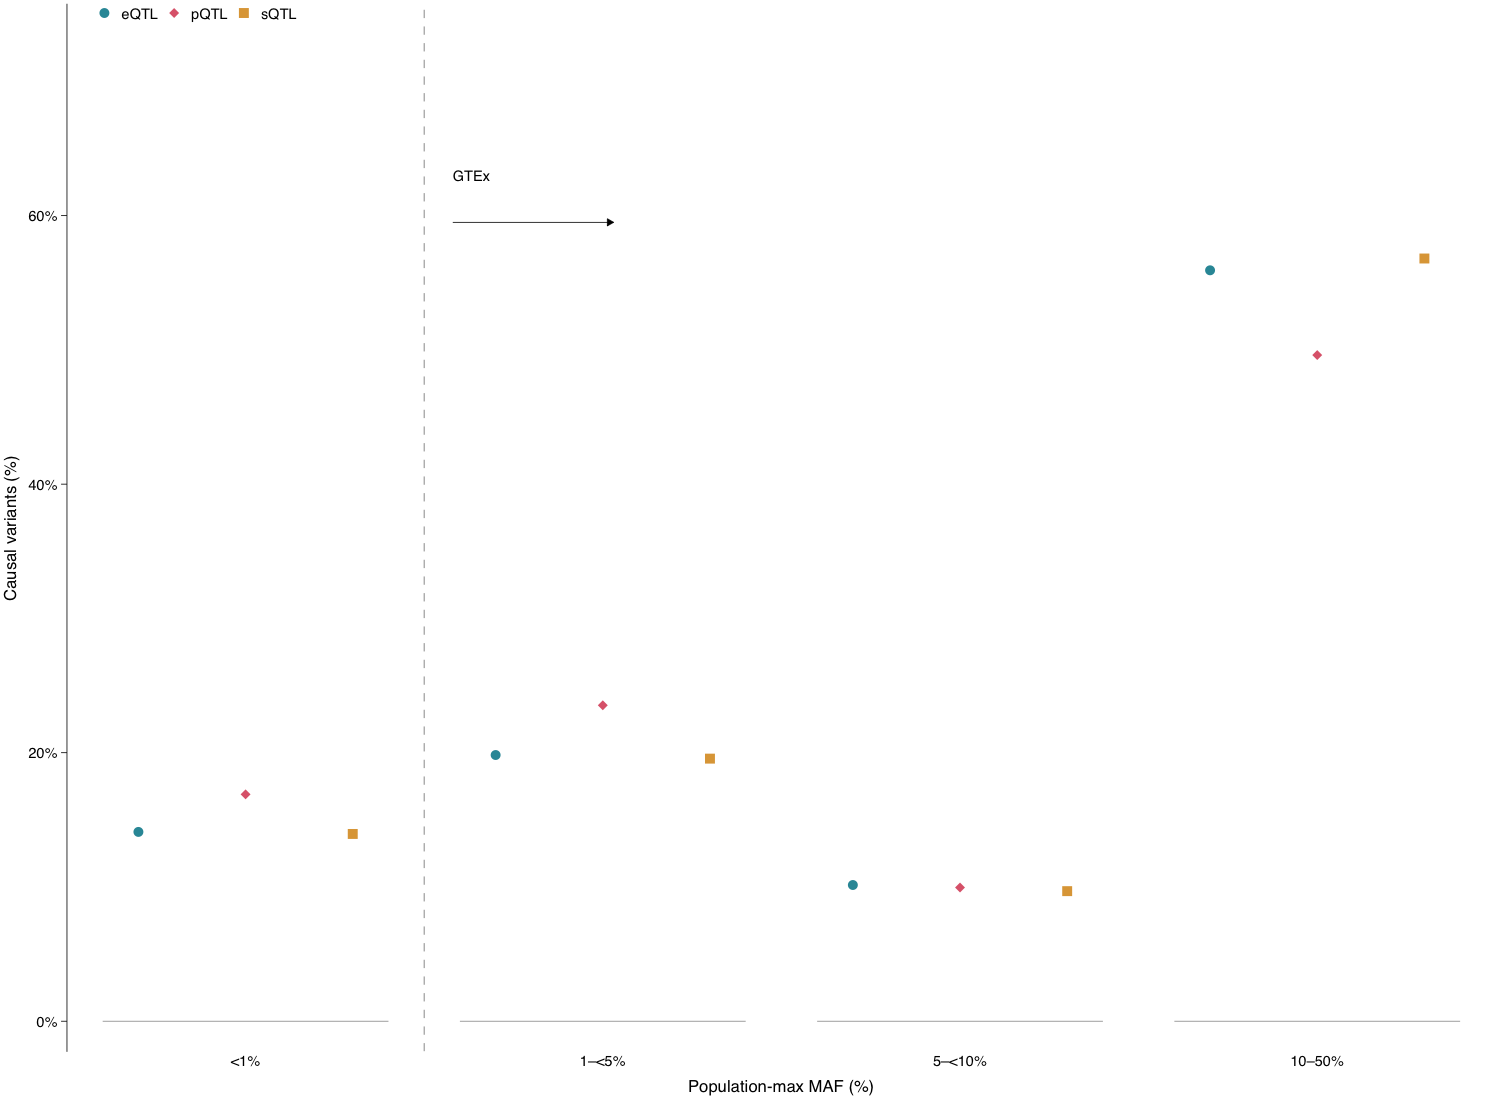

In [8]:
save_plot(plots$A, "Fig2/panel_A", 150, 105)
print(plots$A)


## Render panel B


Export aggregate plot: Fig2/panel_B


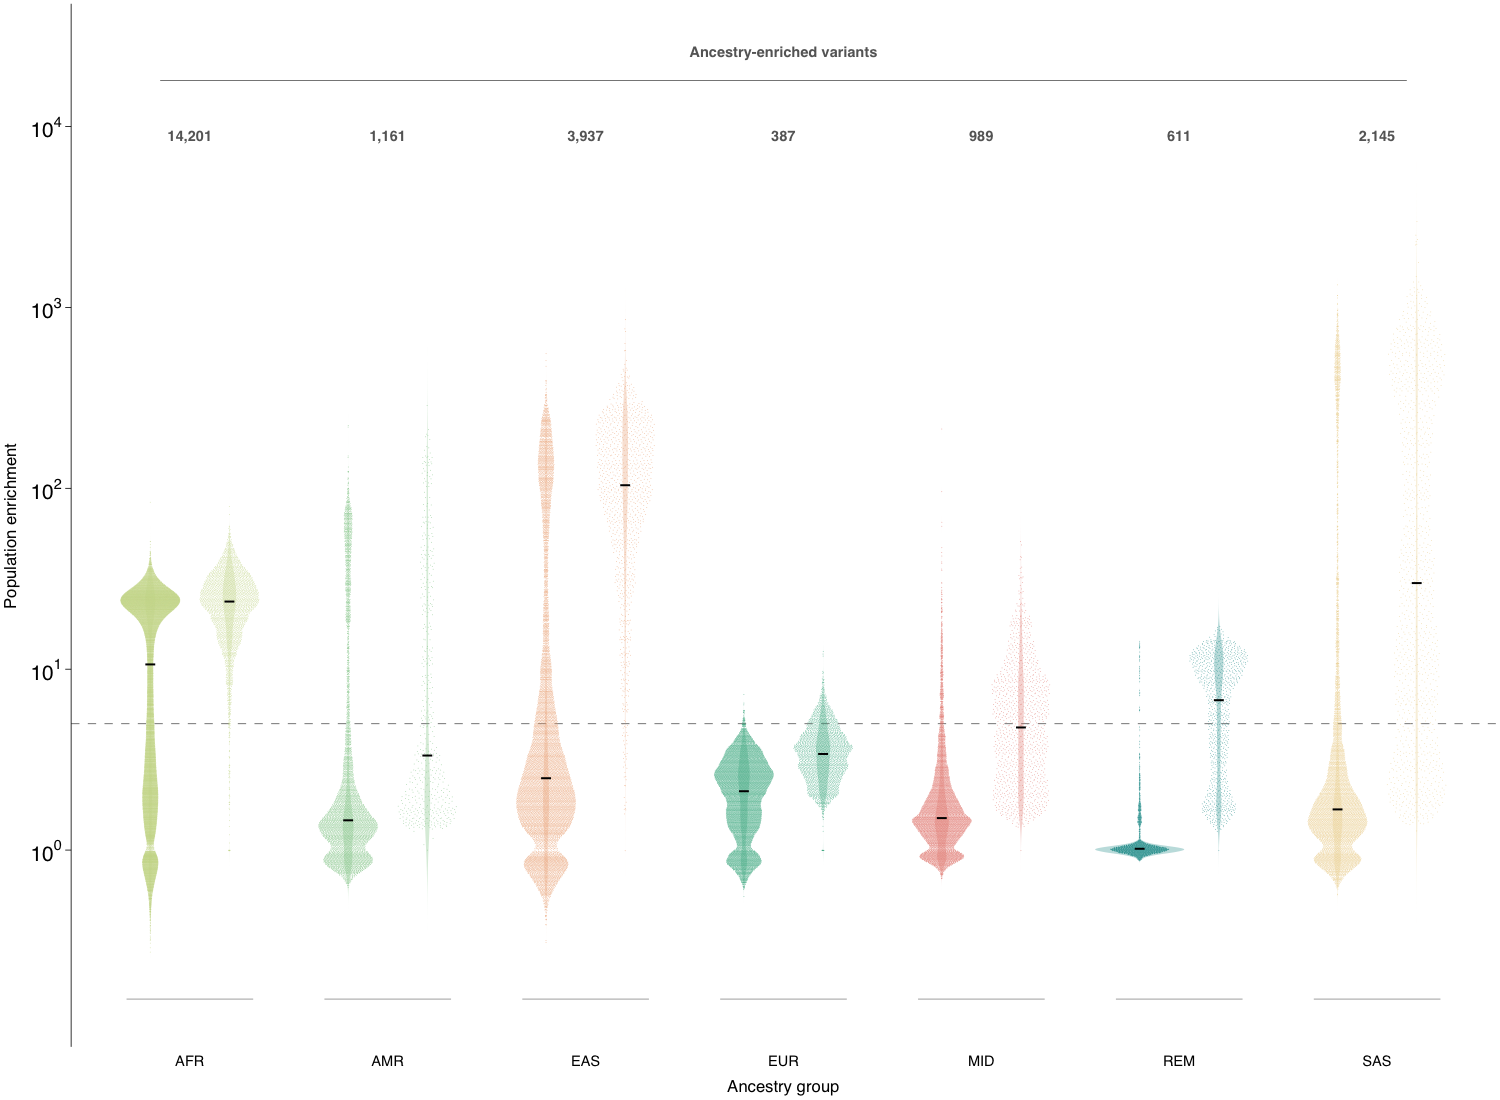

In [9]:
save_plot(plots$B, "Fig2/panel_B", 150, 105)
print(plots$B)


## Render panel C

Clip the distributions at 2. Keep the statistical labels in the right
margin, as in the current vector export. Do not clip the entire panel grob.


Export aggregate plot: Fig2/panel_C


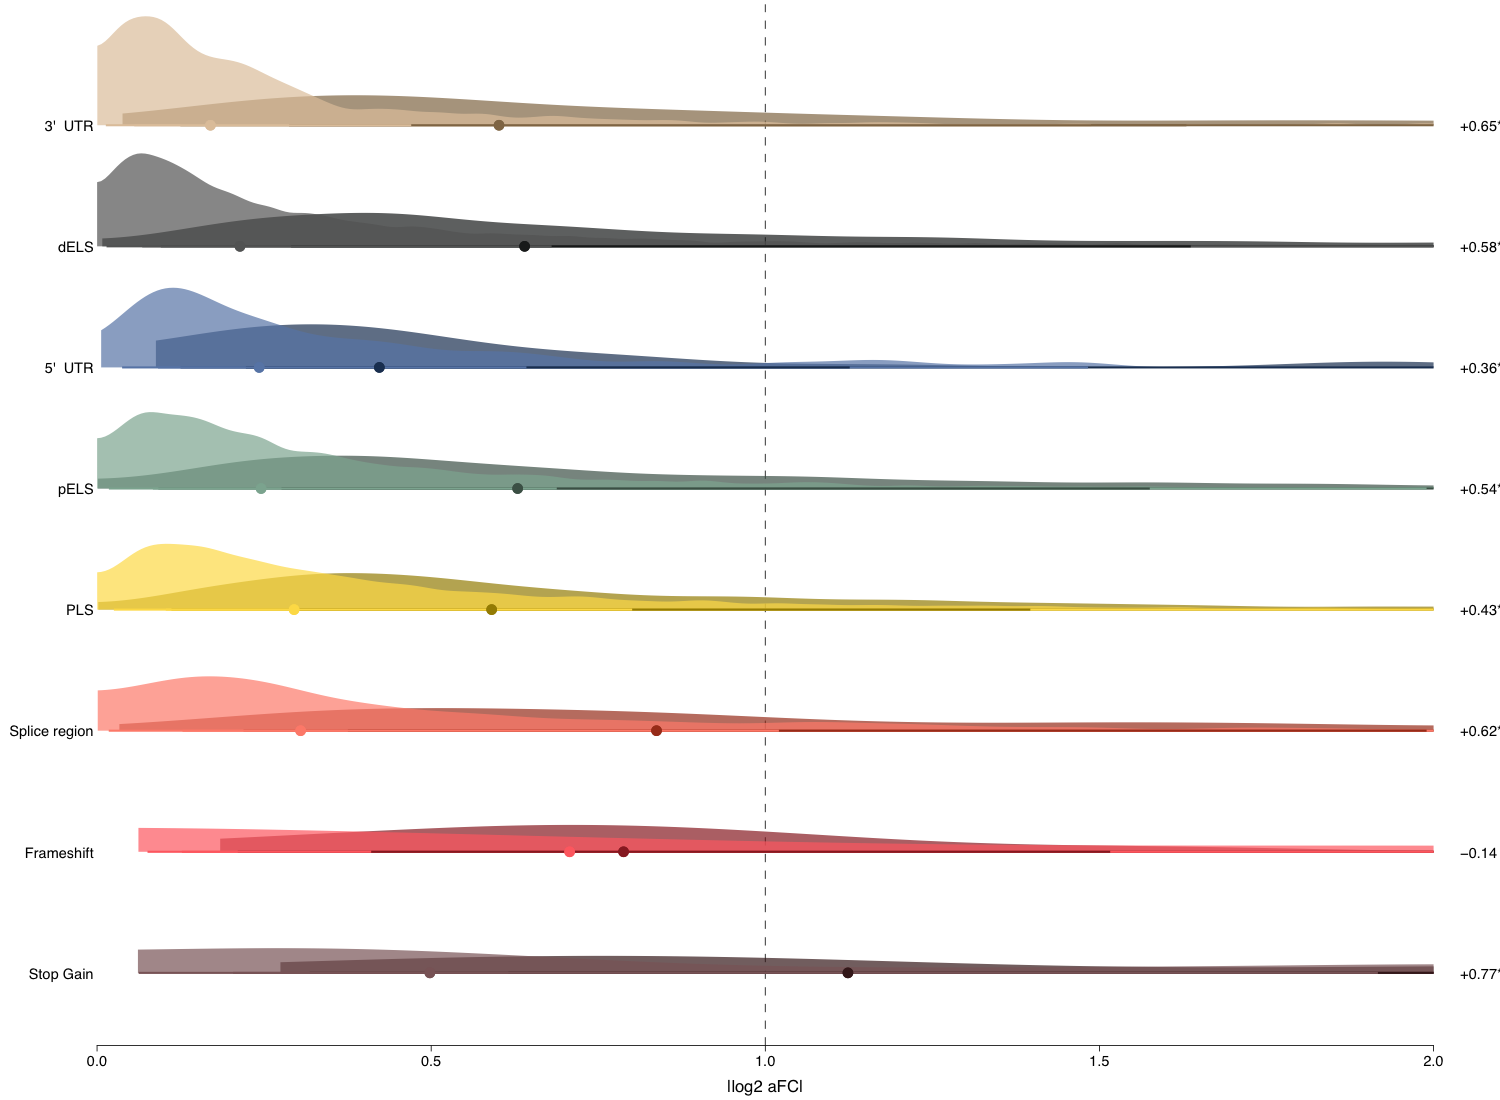

In [10]:
render_panel_C <- function(plot) {
  result <- ggplot2::ggplotGrob(plot)
  index <- which(result$layout$name == 'panel')
  panel <- result$grobs[[index]]
  is_text <- vapply(panel$children, inherits, logical(1), what = 'text')
  stopifnot(sum(is_text) == 1)
  geometry <- do.call(grid::grobTree,
                     c(unname(as.list(panel$children[!is_text])),
                       list(vp = grid::viewport(clip = 'on'))))
  panel <- grid::setChildren(panel, do.call(grid::gList,
                            c(list(geometry), unname(as.list(panel$children[is_text])))))
  if (!is.null(panel$vp)) panel$vp$clip <- FALSE
  result$grobs[[index]] <- panel
  result$layout$clip[[index]] <- 'off'
  result
}
c_artwork <- render_panel_C(plots$C)
save_plot(c_artwork, "Fig2/panel_C", 150, 105)
grid::grid.newpage()
grid::grid.draw(c_artwork)


## Render panel D


Export aggregate plot: Fig2/panel_D


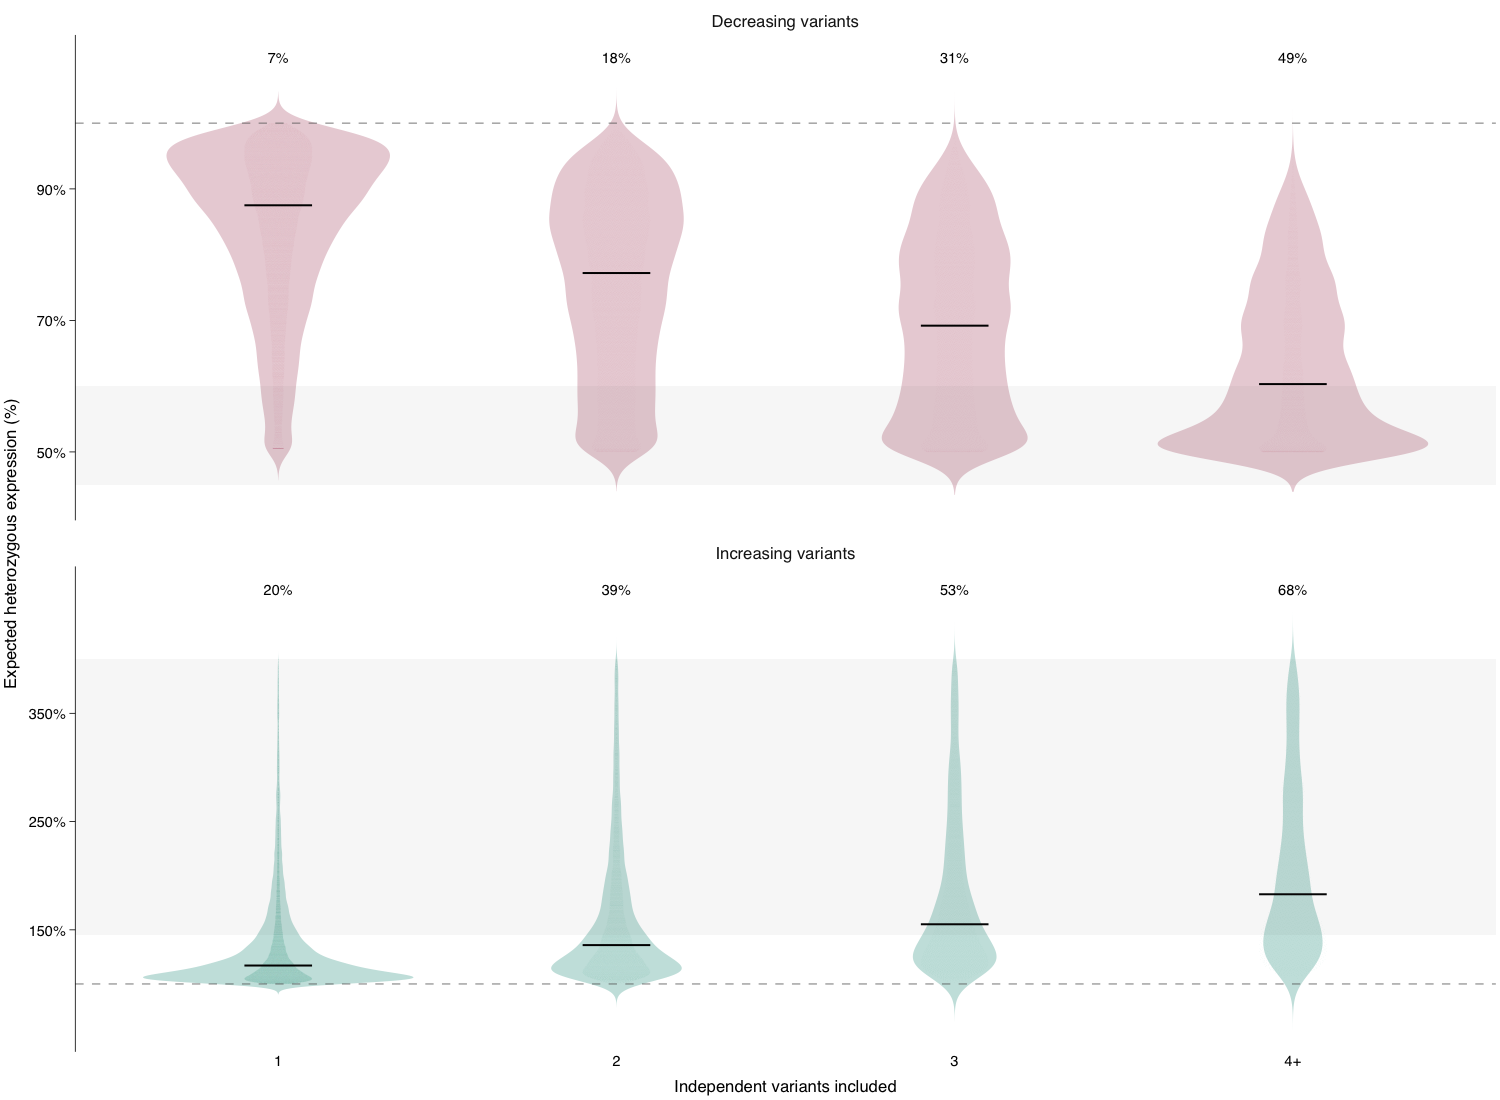

In [11]:
save_plot(plots$D, "Fig2/panel_D", 150, 105)
print(plots$D)


## Outlier enrichment and burden

Align E and F on the same expression-bin centers. The central reference bin is omitted from E.


Export aggregate plot: Fig2/panels_EF


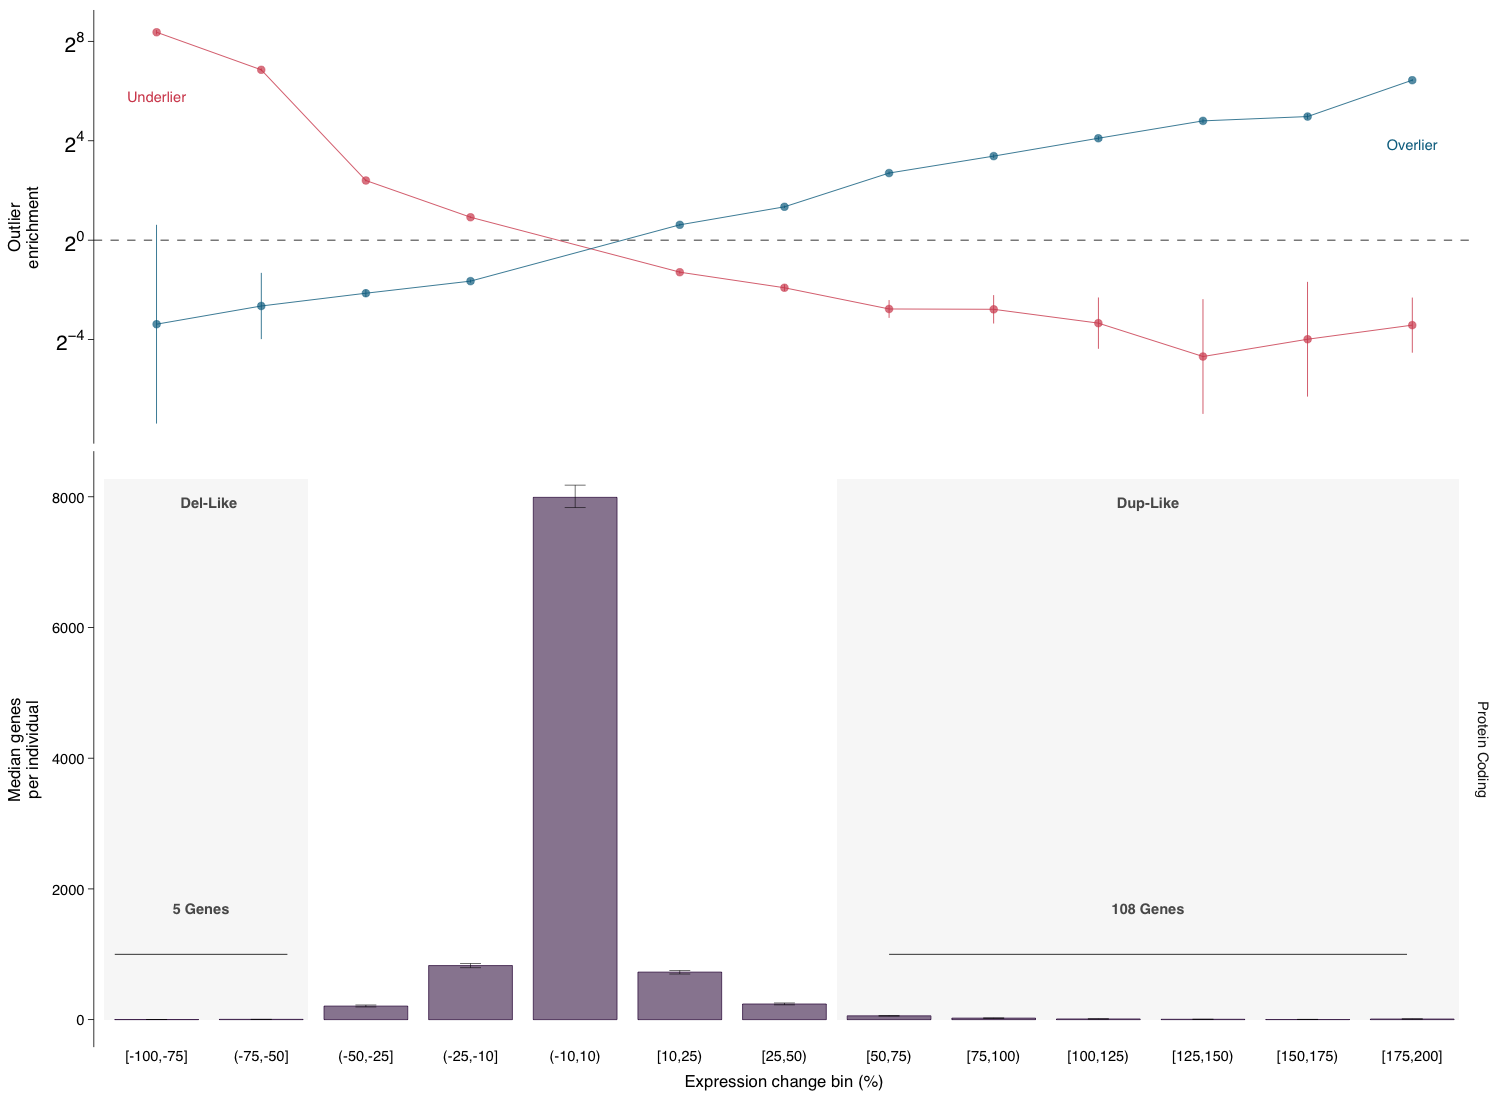

In [12]:
ef <- (plots$E / plots$F) + plot_layout(heights = c(24, 33))
save_plot(ef, "Fig2/panels_EF", 183, 90)
print(ef)


## Rebuild the compact layout


Export aggregate plot: Fig2/Figure2_rebuilt


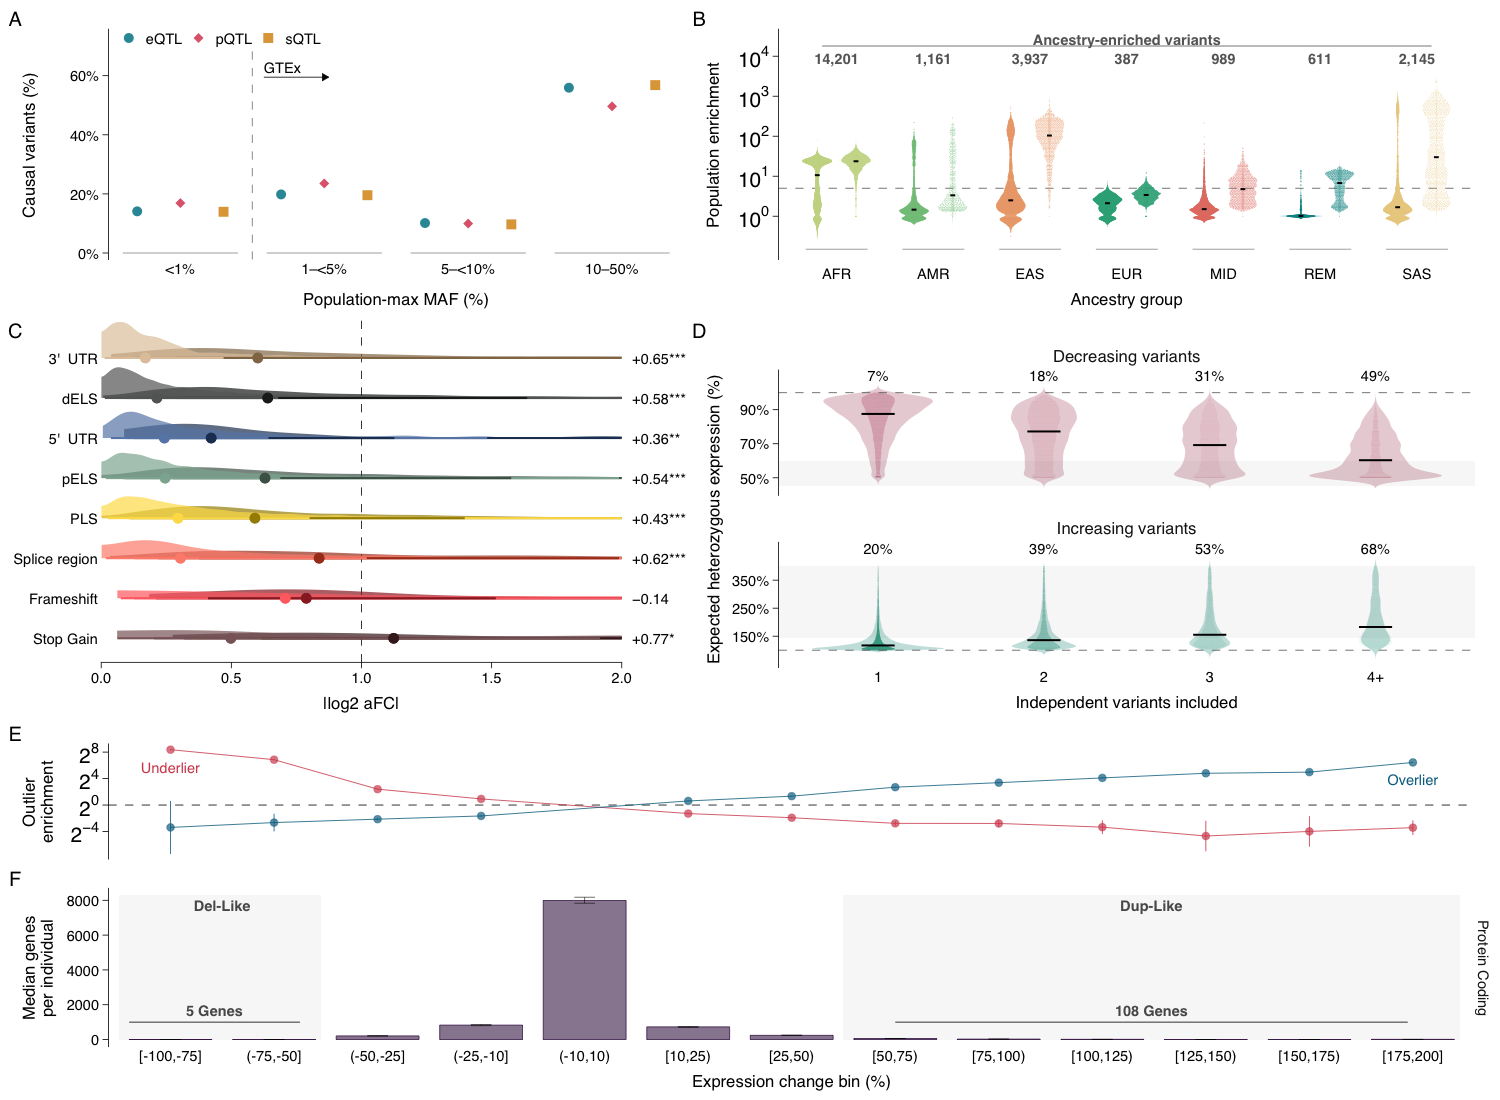

In [13]:
layout_plots <- plots
layout_plots$C <- wrap_elements(full = c_artwork)
fig2 <- wrap_plots(layout_plots, design = "AB\nCD\nEE\nFF", widths = c(81, 98), heights = c(48, 62, 24, 33)) + plot_annotation(tag_levels = "A")
save_plot(fig2, "Fig2/Figure2_rebuilt", 183, 188)
print(fig2)


## Reference figure

Complete figure layout.


Display reference Figure 2.


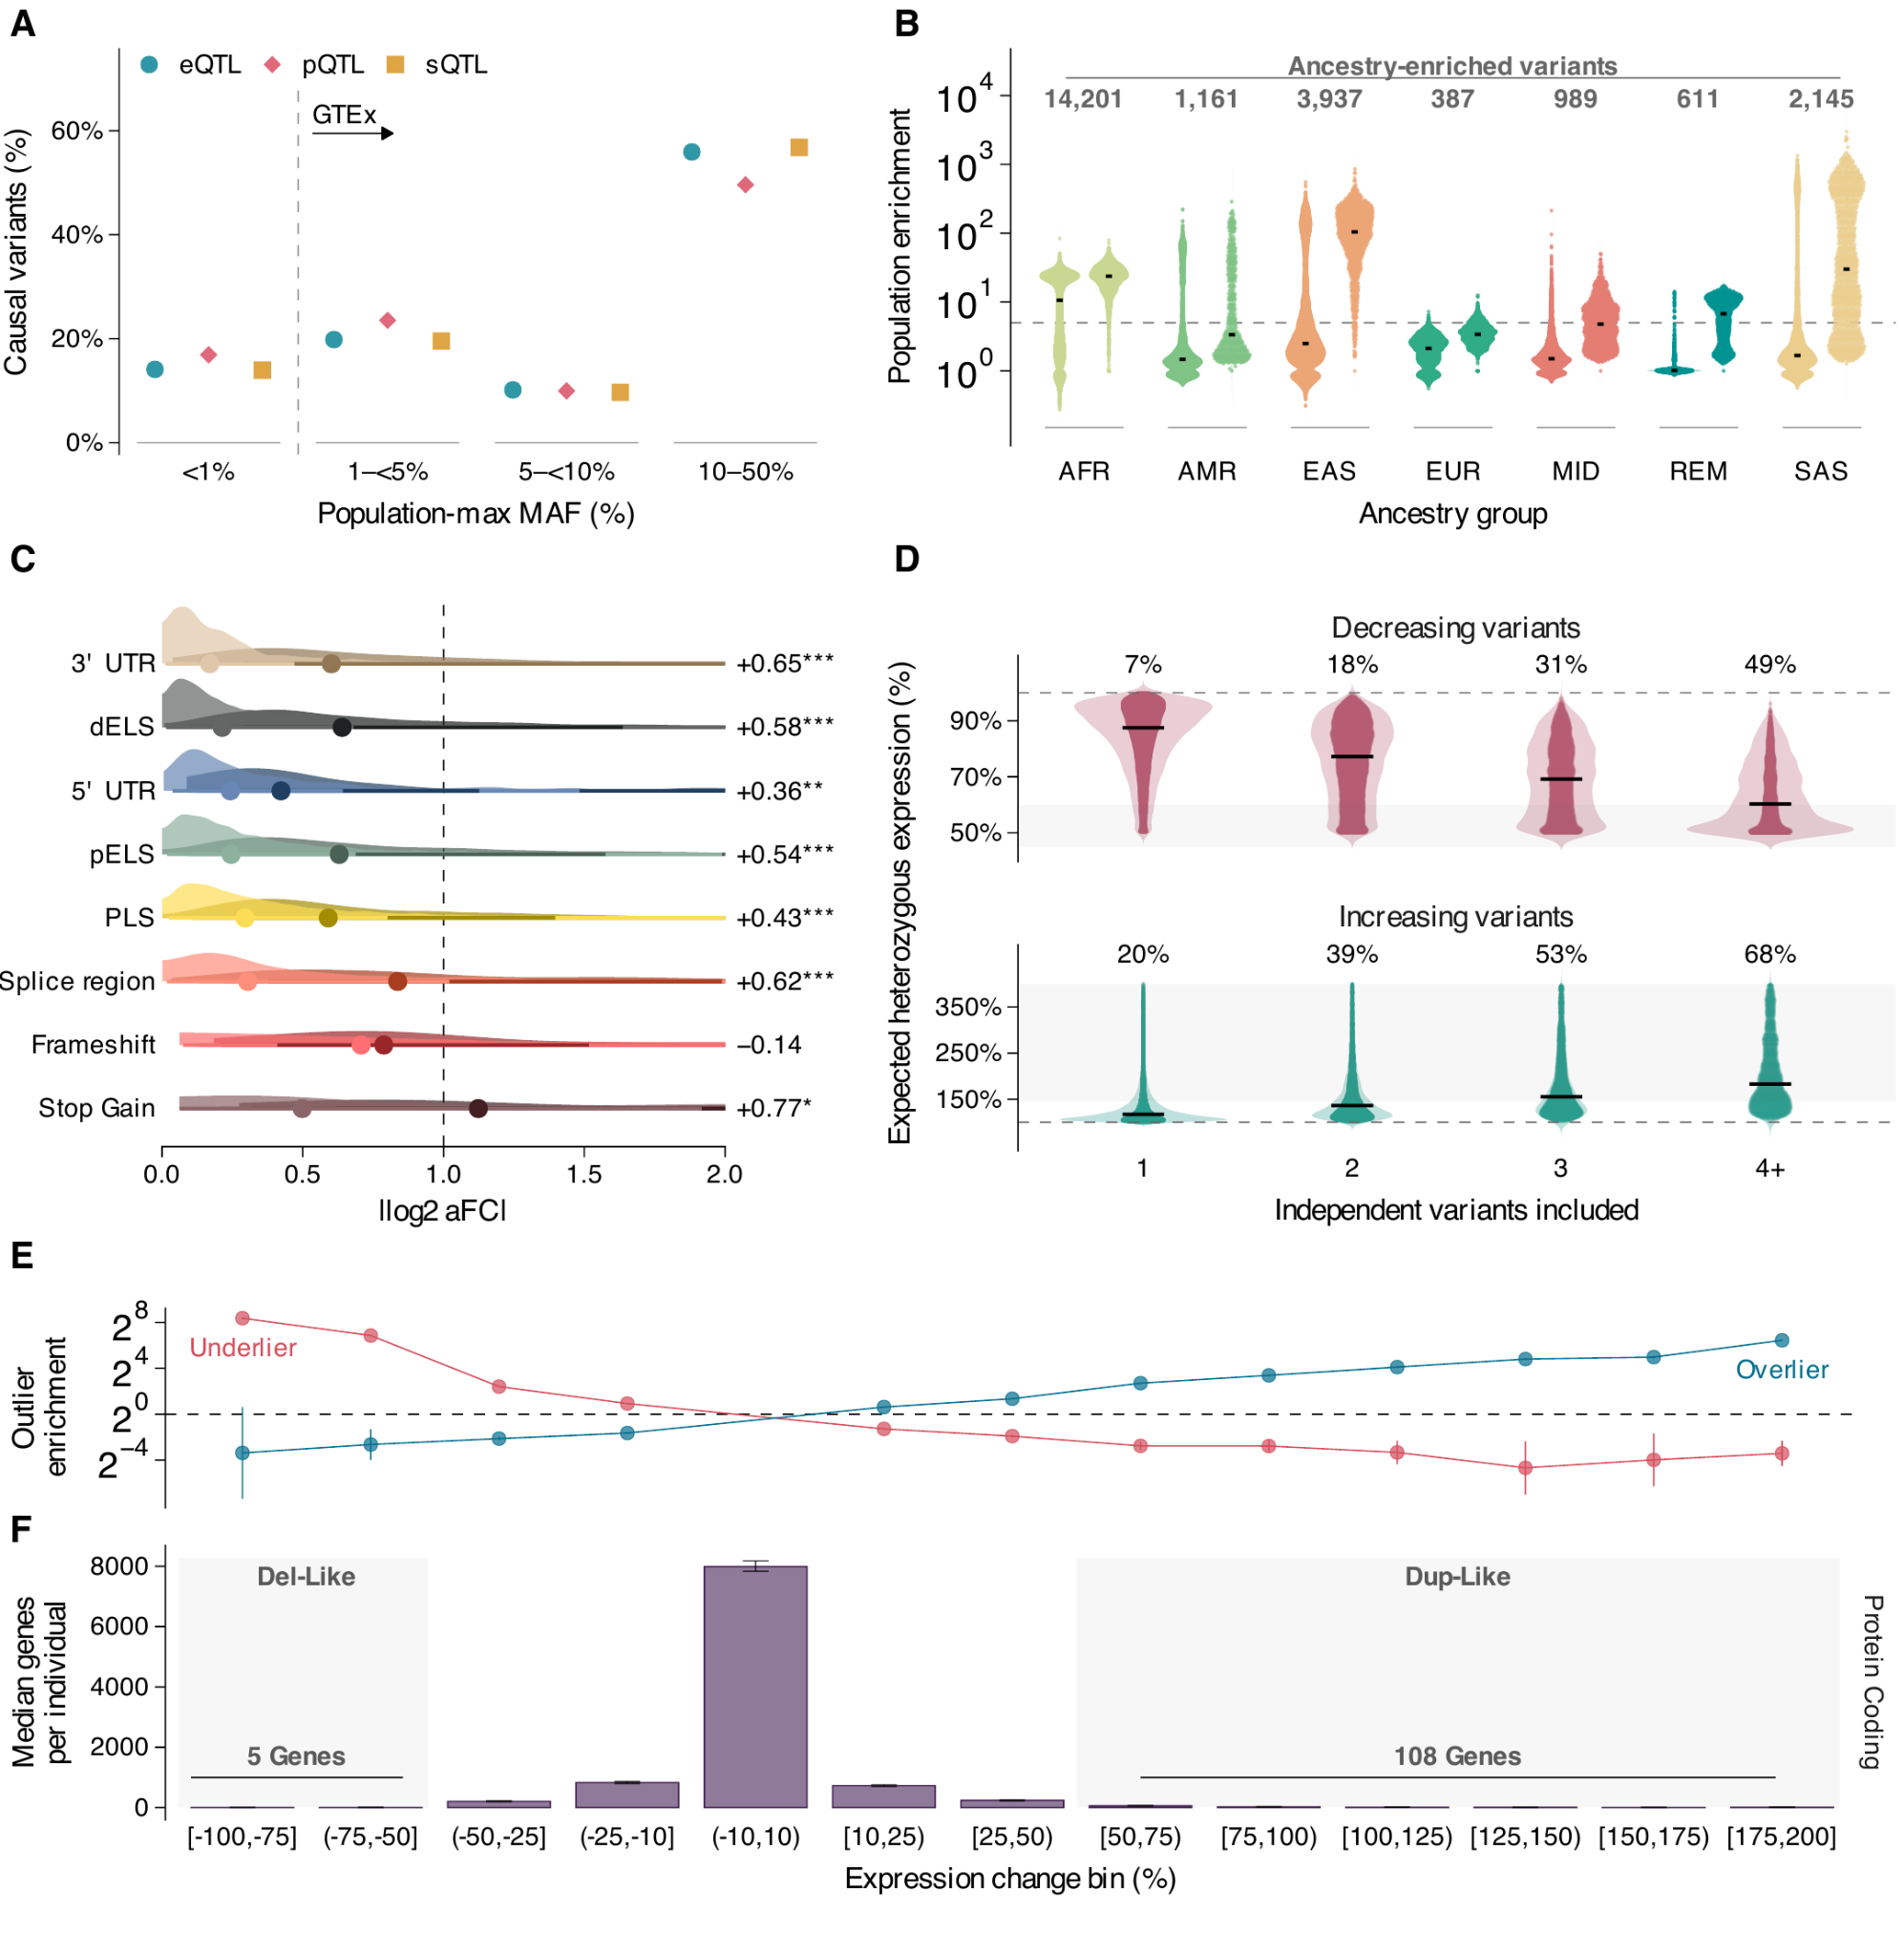

In [14]:
show_reference(2)
